In [1]:
import polars as pl
import pandas as pd
import geopandas as gpd
from shapely.geometry import Polygon, MultiPolygon
import matplotlib.pyplot as plt
import sys
sys.path.append("..")
import utils as ut
import network_merger as nm

In [2]:

foursquare = pl.read_parquet('../data/input_files/uk_foursquare_datefields_admin_categories.parquet')
overture = pl.read_parquet('../data/input_files/poi_uk_overture_proc.parquet')  

foursquare = foursquare.filter((foursquare['level1_category_name'] == 'Retail') | (foursquare['level1_category_name'] == 'Dining and Drinking') )
overture = overture.filter((overture['level1_category_name'] == 'retail') | (overture['level1_category_name']== 'eat_and_drink') )

foursquare = ut.add_h3_11_column(foursquare)
overture = ut.add_h3_11_column(overture)


foursquare_cells = ut.agg_to_cells(foursquare)
overture_cells = ut.agg_to_cells(overture)


#load land use data
land_use_cells = pd.read_parquet('../data/input_files/retail_landuse_h3.parquet')
land_use_cells = pl.DataFrame(land_use_cells)



combined = ut.create_combined_table(foursquare_cells, overture_cells, land_use_cells)

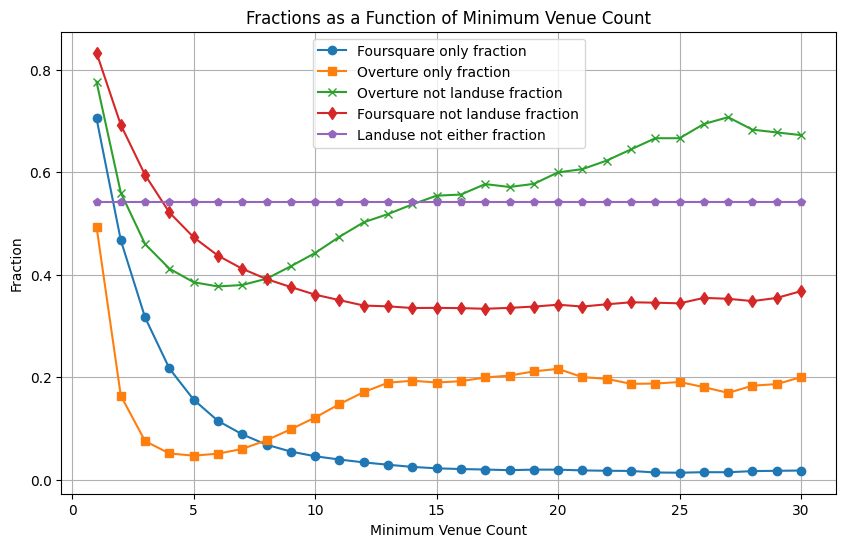

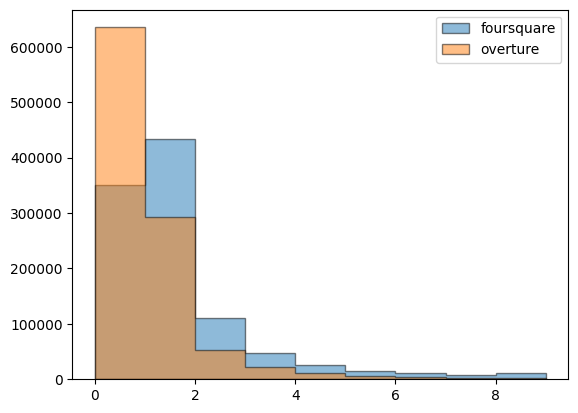

In [3]:

def plot_fractions(combined, max_min_venue_count):
    min_venue_counts = range(1, max_min_venue_count + 1)
    foursquare_only_fractions = []
    overture_only_fractions = []
    overture_not_landuse_fractions = []
    foursquare_not_landuse_fractions = []
    land_use_not_either_fractions = []

    for min_retail_venues in min_venue_counts:
        # Fraction for 'foursquare_count' but not in 'overture_count'
        fsq_only_fraction = (
            combined.filter(pl.col("foursquare_count") >= min_retail_venues)
            .filter(pl.col("overture_count") == 0)
            .height
            / combined.filter(pl.col("foursquare_count") >= min_retail_venues).height
        )
        foursquare_only_fractions.append(fsq_only_fraction)

        # Fraction for 'overture_count' but not in 'foursquare_count'
        overt_only_fraction = (
            combined.filter(pl.col("overture_count") >= min_retail_venues)
            .filter(pl.col("foursquare_count") == 0)
            .height
            / combined.filter(pl.col("overture_count") >= min_retail_venues).height
        )
        overture_only_fractions.append(overt_only_fraction)

        # Overture but not landuse
        overture_not_landuse = (
            combined.filter(pl.col("overture_count") >= min_retail_venues)
            .filter(pl.col("retail_landuse") == False)
            .height
            / combined.filter(pl.col("overture_count") >= min_retail_venues).height
        )
        overture_not_landuse_fractions.append(overture_not_landuse)

        # Foursquare but not landuse
        foursquare_not_landuse = (
            combined.filter(pl.col("foursquare_count") >= min_retail_venues)
            .filter(pl.col("retail_landuse") == False)
            .height
            / combined.filter(pl.col("foursquare_count") >= min_retail_venues).height
        )
        foursquare_not_landuse_fractions.append(foursquare_not_landuse)

        # Landuse but not either
        land_use_not_either = (
            combined.filter(pl.col("retail_landuse") == True)
            .filter((pl.col("foursquare_count") == 0) & (pl.col("overture_count") == 0))
            .height
            / combined.filter(pl.col("retail_landuse") == True).height
        )
        land_use_not_either_fractions.append(land_use_not_either)

    # Plot the results
    plt.figure(figsize=(10, 6))
    plt.plot(min_venue_counts, foursquare_only_fractions, label="Foursquare only fraction", marker="o")
    plt.plot(min_venue_counts, overture_only_fractions, label="Overture only fraction", marker="s")
    plt.plot(min_venue_counts, overture_not_landuse_fractions, label="Overture not landuse fraction", marker="x")
    plt.plot(min_venue_counts, foursquare_not_landuse_fractions, label="Foursquare not landuse fraction", marker="d")
    plt.plot(min_venue_counts, land_use_not_either_fractions, label="Landuse not either fraction", marker="p")
    plt.xlabel("Minimum Venue Count")
    plt.ylabel("Fraction")
    plt.title("Fractions as a Function of Minimum Venue Count")
    plt.legend()
    plt.grid(True)
    plt.show()

# Example usage
plot_fractions(combined, 30)


overture_cells

#plot hist of retail_count (0,10)
plt.hist(combined['foursquare_count'], bins=range(0, 10), alpha=0.5, label='foursquare', histtype = 'stepfilled', edgecolor='black')
plt.hist(combined['overture_count'], bins=range(0, 10), alpha=0.5, label='overture', histtype = 'stepfilled', edgecolor='black')
plt.legend(loc='upper right')
plt.show()

## filter cells

In [4]:
min_retail_venues = 2
input_cells = combined.filter(
    (pl.col("foursquare_count") >= min_retail_venues) | (pl.col("retail_landuse") == True)
)

In [5]:
# Example usage
cells_with_network = ut.create_networks(input_cells)

In [11]:
cells_with_network


h3_11,network_number,trackNodes,foursquare_count,retail_landuse,overture_count,total_overture_count,total_foursquare_count,trackNodes_right
str,i64,i64,u32,bool,u32,u32,u32,u32
"""8b09a6b61393fff""",60,63,2,true,0,34,28,63
"""8b09a6b613a2fff""",60,63,0,true,0,34,28,63
"""8b09a6b61669fff""",60,63,1,true,2,34,28,63
"""8b09a6b6164efff""",60,63,0,true,0,34,28,63
"""8b09a6b61292fff""",60,63,0,true,0,34,28,63
…,…,…,…,…,…,…,…,…
"""8b1976d81d93fff""",108184,26,1,true,3,33,65,26
"""8b1976d81d9afff""",108184,26,4,true,1,33,65,26
"""8b1976d81d90fff""",108184,26,10,true,3,33,65,26


In [7]:
left = cells_with_network[1]
left

h3_11,network_number,trackNodes,foursquare_count,retail_landuse,overture_count,total_overture_count,total_foursquare_count,trackNodes_right
str,i64,i64,u32,bool,u32,u32,u32,u32
"""8b09a0919982fff""",1,3,0,true,0,0,0,3


In [ ]:
#rename overture_count to total_retail_count

df = cells_with_network

#island rmeoval
#keep only the networks with more than 10 retail venues or more than 1 track node 
#We prune the exhaustive set of retail cen-
#tres to include only those with at least two hexagon units and at least ten overall retail unit points contained
#within them, a threshold used by Pavlis et al. (2018) and based on UK retail planning policy 18 . 
cells_with_network = df.filter(((df['total_foursquare_count'] >= 10) | (df['trackNodes'] >= 2)) & (df['total_foursquare_count'] >= 15)).sort("network_number")

#"In England and Wales, agglomerations with less than
#fifteen VOA retail points and ten OSM retail points are removed from the set, while for Scotland and Northern
#Ireland the condition is based on ten OSM points."""
#from https://www.ons.gov.uk/peoplepopulationandcommunity/populationandmigration/populationestimates/articles/highstreetsingreatbritain/march2020
#Spatial clustering has been implemented using the data clustering algorithm DBSCAN (Density-based spatial clustering of applications with noise). Candidate retail clusters required a minimum of 15 retail address point geometries within 15 buildings and a maximum of 150 metres between the address geometries in the cluster.


# ut.to_parquet(df, 'uk_overture_retail_networks_test')

(array([17632., 22043., 17838., 16991., 15817., 15701., 13405., 12061.,
        11688., 11528.,  8296.,  5622.,  5081.,  6980.,  5909.,  5565.,
         6070.,  5401.,  3880.,  3114.,  2229.,  3216.,  2925.,  2585.,
         1221.,  1536.,  1855.,   822.,  1715.]),
 array([  0.,  10.,  20.,  30.,  40.,  50.,  60.,  70.,  80.,  90., 100.,
        110., 120., 130., 140., 150., 160., 170., 180., 190., 200., 210.,
        220., 230., 240., 250., 260., 270., 280., 290.]),
 [<matplotlib.patches.Polygon at 0x7f3ed804f290>])

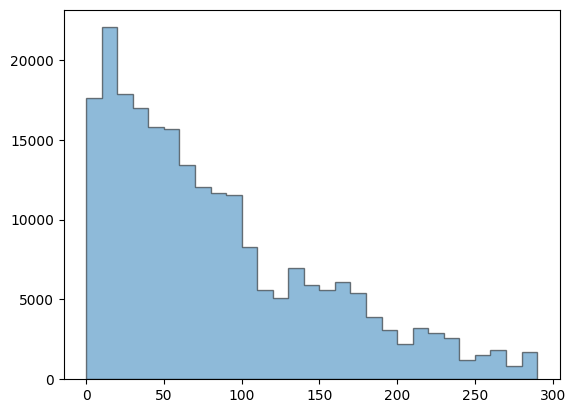

In [9]:
#hist trackNodes
#from 0-300, 50 bins
plt.hist(cells_with_network['trackNodes'], alpha=0.5, label='trackNodes', histtype = 'stepfilled', edgecolor='black', bins=range(0, 300, 10))

In [8]:
ut.to_parquet(cells_with_network,"before_merge")

In [10]:
merged_data = nm.merge_networks_separated_by_one_cell(cells_with_network)

Merging networks separated by one cell.
Getting the perimeter of the networks.
Finding overlapping networks and overlap.


KeyboardInterrupt: 

In [10]:
ut.to_parquet(merged_data, 'after_merge')

In [10]:
filled_data = nm.fill_until_no_new_cells(merged_data)

Iteratively adding cells, with 5 or more neighbours to the network.
Run  1
Adding 3811 cells.
Run  2
Adding 570 cells.
Run  3
Adding 124 cells.
Run  4
Adding 22 cells.
Run  5
Adding 7 cells.
Run  6
Adding 4 cells.
Run  7
Adding 1 cells.
Run  8
Adding 1 cells.
Run  9
No new cells added.


In [15]:
filled_data
import utils as ut

In [12]:
with_info = ut.join_networks_with_cells_left(filled_data, combined)

In [ ]:
with_info

In [31]:
ut.to_parquet(filled_data, 'after_fill_full5')

In [37]:
filled_data4 = fill_until_no_new_cells(merged_data, min_neighbours=4)

Run  1
adding  13814  cells
Run  2
adding  2908  cells
Run  3
adding  867  cells
Run  4
adding  419  cells
Run  5
adding  231  cells
Run  6
adding  128  cells
Run  7
adding  72  cells
Run  8
adding  37  cells
Run  9
adding  19  cells
Run  10
adding  9  cells
Run  11
adding  6  cells
Run  12
adding  4  cells
Run  13
adding  2  cells
Run  14
adding  1  cells
Run  15
adding  1  cells
Run  16
adding  0  cells


In [38]:
ut.to_parquet(filled_data4, 'after_fill_full4')

In [17]:
df = ut.to_geoframe(filled_data4)
dissolved = (
    df
    .dissolve(by='network_number', as_index=False)
    .reset_index(drop=True)
)

dissolved['geometry'] = dissolved['geometry'].apply(lambda geom: ut.fill_holes(geom))

# Final GeoDataFrame with dissolved unique polygons
dissolved_unique_gdf = gpd.GeoDataFrame(dissolved, geometry='geometry', crs='EPSG:27700')
dissolved_unique_gdf.to_parquet('../data/output_files/uk_overture_retail_networks_dissolved_merged.parquet')